## =====================================
## Восстанавливаем поля по зашумленным RM
## =====================================

### Векторный потенциал     $A = (0, A_\phi, 0) $ 
 > ↓ $B = Rot(A) = (-\frac{dA_\phi}{dz}, 0, \frac{1}{\rho} \frac{d}{d\rho}(\rho A_\phi))$

### Истинные поля:          ${B_{\phi}}^{true}, {B_{z}}^{true} $
 > ↓ прямая задача 

### Истинная RM:            $B_\phi \rightarrow  RM_{odd} ,\ B_z \rightarrow RM_{even}$, $| RM = RM_{odd} + RM_{even}$
                            
> ↓ добавляем шум на B 

### Зашумлённые поля:       $B_{phi}^{noise}, B_z^{noise}$
> ↓ прямая задача 

### Наблюдаемая RM:         $RM_{odd}^{obs}, RM_{even}^{obs}$  ← вход для обратной задачи 
 > ↓ обратная задача (регуляризация) 

### Восстановленные поля:   $B_\phi^{rec}, B_z^{rec} $
 > ↓ прямая задача

# ---------------------------------------------

In [34]:
# ==============================================================================
# 1: Импорты
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from Magnetic_Field import (
    make_A_phi, A_phi_gaussian, A_phi_uniform, A_phi_power, A_phi_screen,
    compute_B_from_A_phi, extract_axial_profiles,
    save_field_to_csv, load_field_from_csv,
    compute_field_from_B
)
from methods import (
    build_operators, forward_rm, regularizer, RegularizedInversion,
    choose_alpha_lcurve, electron_density, rel_error, relative_error,
    add_noise, plot_recovery, plot_sweep, plot_A_and_B,
    plot_A_phi_profiles, plot_B_profiles, 
    append_run_to_csv, load_runs,
    plot_all_true_fields, plot_all_recovered_fields,
    plot_all_rm, plot_all_rm_noisy,
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('default')

print("✅ Модули загружены.")



✅ Модули загружены.


In [35]:
from calculate import Calculate

#### ==============================================================================
#### 2: >>> ВЕКТОРНЫЙ ПОТЕНЦИАЛ A_phi <<<
#### ==============================================================================


 | type | Потенциал | Ожидаемое B_z |
 |---|---|---|
 | 1 | `A0·ρ` | постоянность |
 | 2 | `A0·ρ²/R` | линейный рост |
 | 3 | `A0·ρ·exp(-ρ/L)` | локальный горб смена знака |

 **Важно про нечётный канал.** Если задан только `A_phi`, то
 `B_phi = rot(A)_phi ≡ 0` тождественно. Поэтому `RM_odd ≡ 0`



def A_phi_gaussian(rho, z, A0=1.0, rho_scale=5.0, z_scale=3.0):
    """A_phi = A0 * rho * exp(-(rho/rho_scale)^2 - (z/z_scale)^2)."""
    return A0 * rho * np.exp(-(rho / rho_scale) ** 2 - (z / z_scale) ** 2)


def A_phi_uniform(rho, z, A0=1.0):
    """A_phi = A0 * rho  ->  однородное B_z = 2*A0."""
    return A0 * rho * np.exp(-z)


def A_phi_power(rho, z, A0=1.0, power=3.0, rho_scale=5.0):
    """A_phi = A0 * rho ^ power """
    return A0 * np.power(rho, power) 

def A_phi_exp(rho, z, A0=1.0, power=2.0, rho_scale=5.0):
    """A_phi = A0 * exp(-rho)."""
    return A0 * np.exp(-rho)


FILENAME = "results/all_runs_var_with A.csv"
 Очистим файл, чтобы не смешивать со старыми запусками
if os.path.exists(FILENAME):
    os.remove(FILENAME)
    
 Список всех вариантов A_phi
variants_A = {
    "uniform":   lambda rho, z, **kw: A_phi_uniform(rho, z, A0=1.0),
    "exp":       lambda rho, z, **kw: A_phi_exp(rho, z, A0=1.0),
    "power2":    lambda rho, z, **kw: A_phi_power(rho, z, A0=1.0, power=2.0, rho_scale=5.0),
}

delta_common = 0.02
 Прогон всех вариантов с одинаковым шумом
for name, func in variants_A.items():
    Calculate(A_phi_func=func, mode="from_A",
              delta= delta_common, plot=False,
              filename=FILENAME, run_name=f"A_{name}", seed=42,
              wrap_with_A0=False)
'''

#### ==============================================================================
#### 1: >>> Поле B_z <<<
#### ==============================================================================

In [36]:
deltas = [0, 0.005, 0.01, 0.02, 0.03, 0.04]

In [37]:
def B_z_constant(rho, B0=1.0):
    return B0 * rho**0

def B_z_gauss(rho, B0=1.0, rho_scale=1.0):
    return B0 * np.exp(-(rho / rho_scale)**2)

def B_z_power2(rho, B0=0.0025):
    return B0 * rho**2

def B_z_gauss_power2(rho, B0=1.0, rho_scale=1.0):
    return B0 * rho**2 * np.exp(-(rho / rho_scale)**2)

variants_B = {
    "B_constant":  B_z_constant,
    r"B_power2_B0_01":  B_z_power2,
    r"B_$e^{-\rho^2}$": B_z_gauss,
    r"B_$\rho^2 e^{-\rho^2}$": B_z_gauss_power2,
}


In [38]:

# имена папок/файлов для каждого метода
REG_TAG = {
    "None": "none",
    "Zero":  "zero_order",
    "First": "first_order",
    "Second": "second_order",
}

In [39]:
name_type = "Second"
RESULTS_DIR = f"results_2110/{name_type}"


def _fname(delta, REG_KIND="second_order"):
    return os.path.join(
        RESULTS_DIR,
        f"(delta 0_05_1_2_3_4)_Bz_all_runs_(var_B)_noise_{delta}_reg_{REG_KIND}.csv"
    )

In [40]:
REF_KIND = REG_TAG[name_type]
if int(input()) == 0:
    for delta_tmp in deltas:
        FILENAME = _fname(delta_tmp, REG_KIND)

        for name, func in variants_B.items():
            Calculate(B_z_func=func, mode="direct",
                    delta=delta_tmp, reg_kind=REG_KIND,
                    plot=False,
                    filename=FILENAME, run_name=name, seed=42)
            

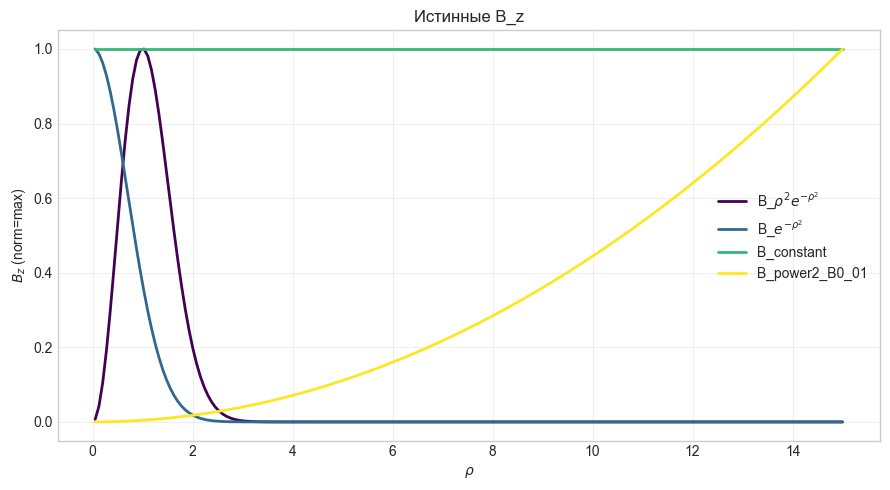

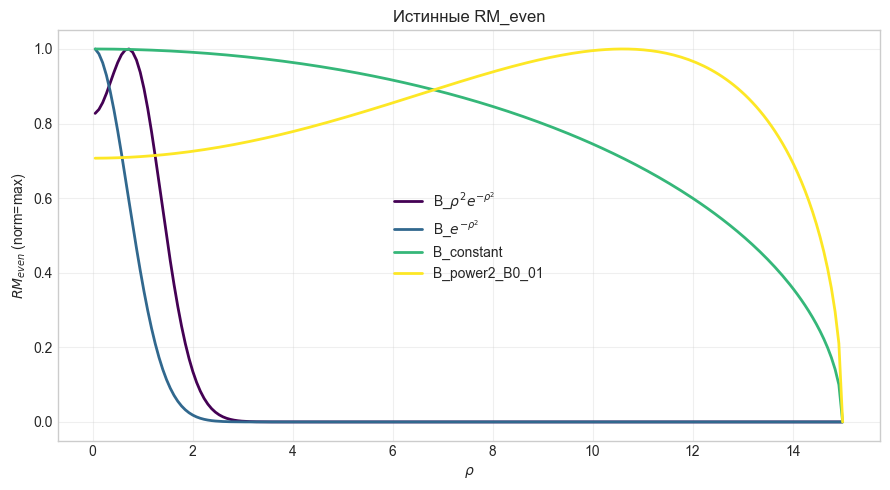

Загружено запусков: ['B_$\\rho^2 e^{-\\rho^2}$', 'B_$e^{-\\rho^2}$', 'B_constant', 'B_power2_B0_01']
Загружено запусков: ['B_$\\rho^2 e^{-\\rho^2}$', 'B_$e^{-\\rho^2}$', 'B_constant', 'B_power2_B0_01']
Загружено запусков: ['B_$\\rho^2 e^{-\\rho^2}$', 'B_$e^{-\\rho^2}$', 'B_constant', 'B_power2_B0_01']
Загружено запусков: ['B_$\\rho^2 e^{-\\rho^2}$', 'B_$e^{-\\rho^2}$', 'B_constant', 'B_power2_B0_01']
Загружено запусков: ['B_$\\rho^2 e^{-\\rho^2}$', 'B_$e^{-\\rho^2}$', 'B_constant', 'B_power2_B0_01']
Загружено запусков: ['B_$\\rho^2 e^{-\\rho^2}$', 'B_$e^{-\\rho^2}$', 'B_constant', 'B_power2_B0_01']


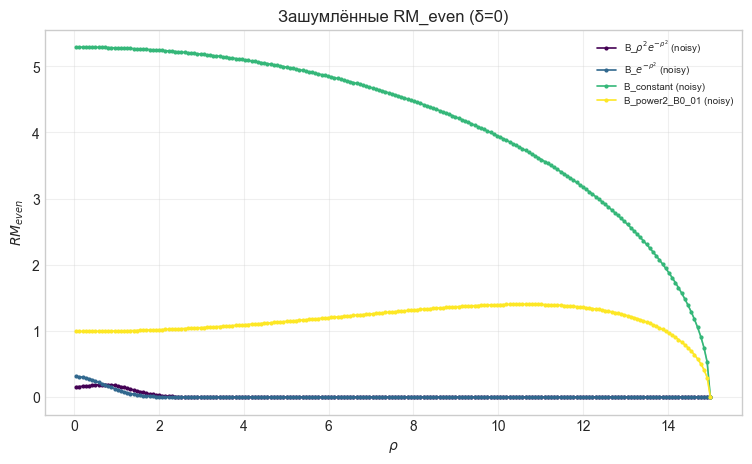

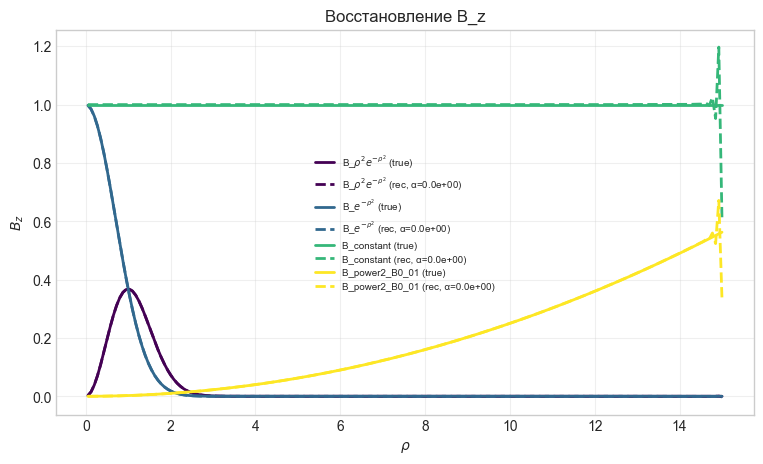

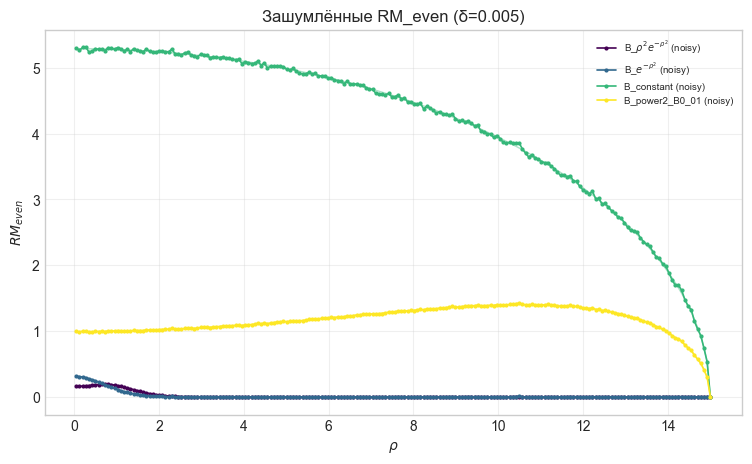

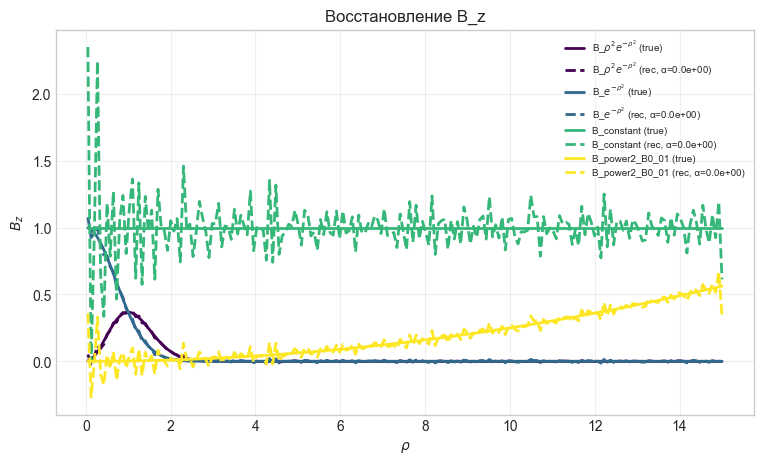

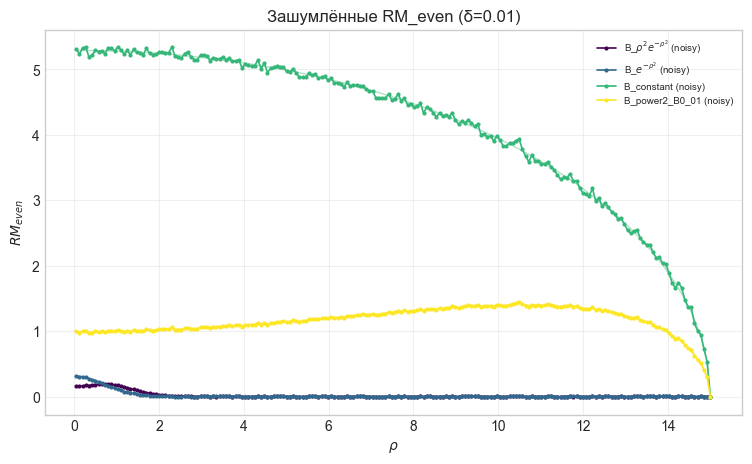

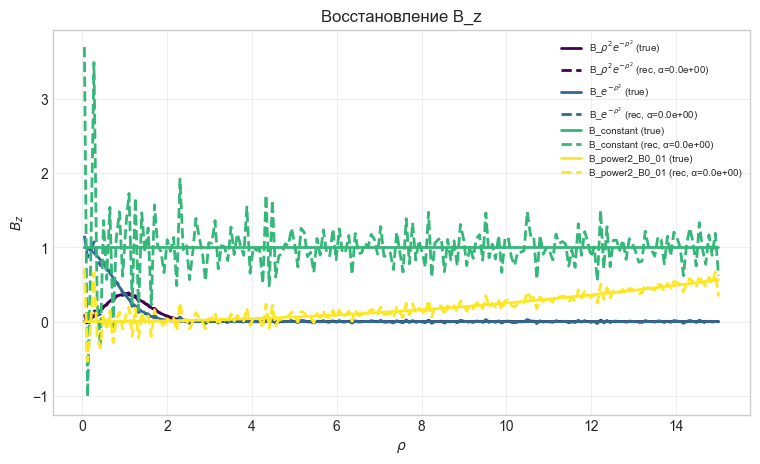

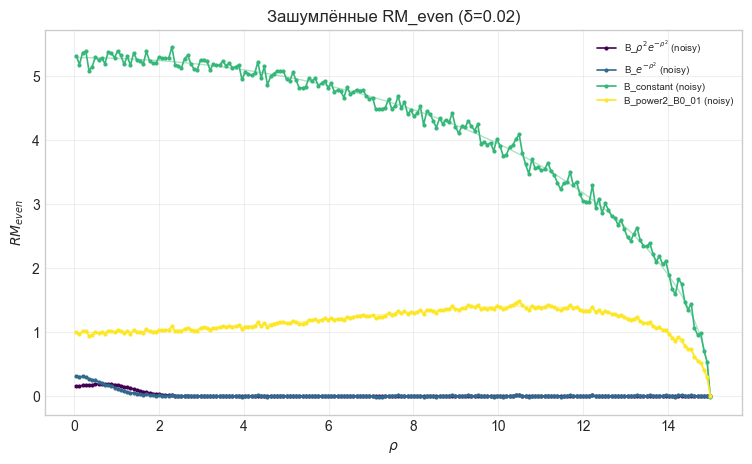

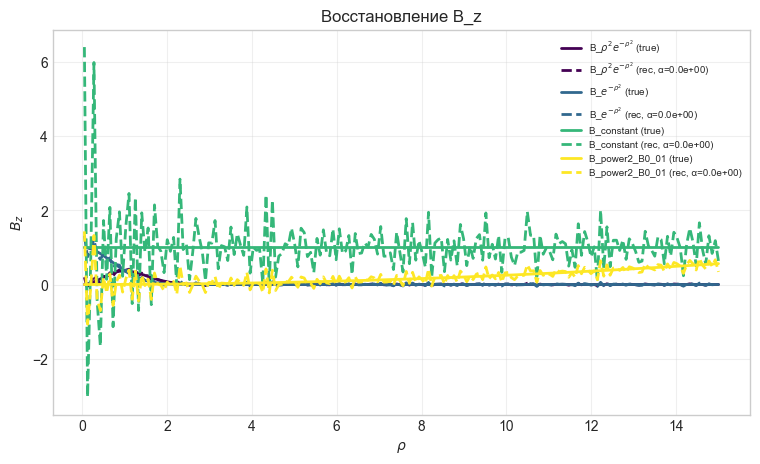

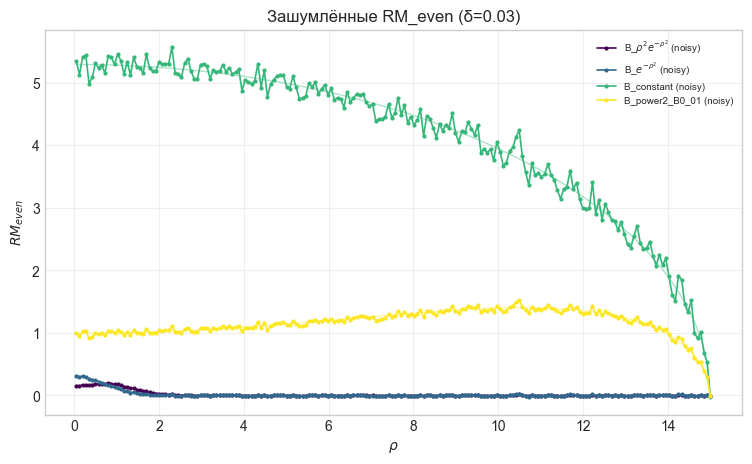

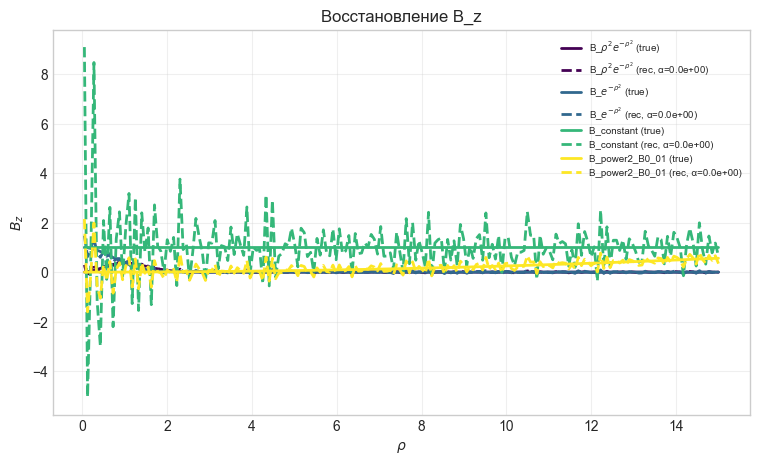

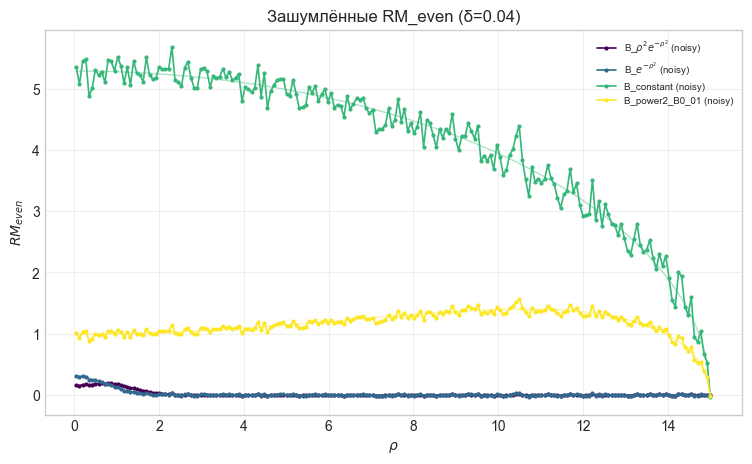

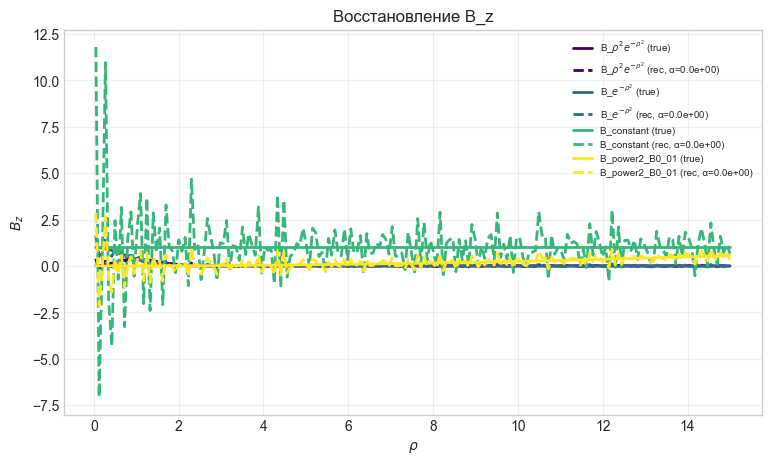

In [41]:
# ==============================================================================
# ЧТЕНИЕ ВСЕХ ЗАПУСКОВ И СВОДНЫЕ ГРАФИКИ
# ==============================================================================
FILENAME = _fname(deltas[0], REG_KIND)
rho, runs = load_runs(FILENAME)

# 1) Все истинные B_z на одном графике
plot_all_true_fields(rho, runs, field_key='B_z_true',
                        ylabel=r'$B_z$',
                        title="Истинные B_z",
                        norm = "max")

# 2) Все RM_even (истинные) на одном графике
plot_all_rm(rho, runs, rm_key='RM_even_true',
            ylabel=r'$RM_{even}$',
            title="Истинные RM_even",
            norm = "max")

for delta_tmp in deltas:
        FILENAME = _fname(delta_tmp,  REG_KIND)
        
        rho, runs = load_runs(FILENAME)
        print(f"Загружено запусков: {list(runs.keys())}")
        
        TYPE_NORM = None # None, "max"
        # 3) Все зашумлённые RM_even на одном графике
        plot_all_rm_noisy(rho, runs,
                        rm_noisy_key='RM_even_noisy',
                        rm_true_key='RM_even_true',
                        ylabel=r'$RM_{even}$',
                        title=f"Зашумлённые RM_even (δ={delta_tmp})",
                        norm = TYPE_NORM)

        # 4) Все восстановленные B_z + истинные — на одном графике
        plot_all_recovered_fields(rho, runs,
                                true_key='B_z_true',
                                rec_key='B_z_rec',
                                ylabel=r'$B_z$',
                                title="Восстановление B_z",
                                norm = TYPE_NORM)

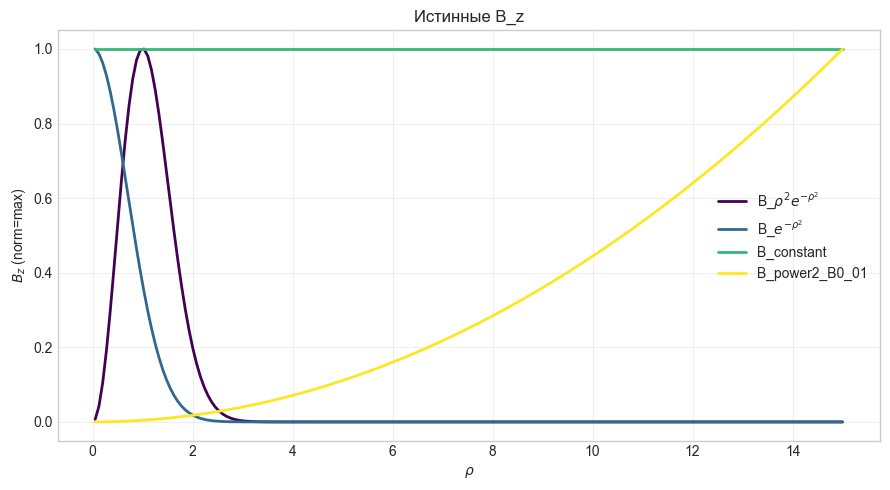

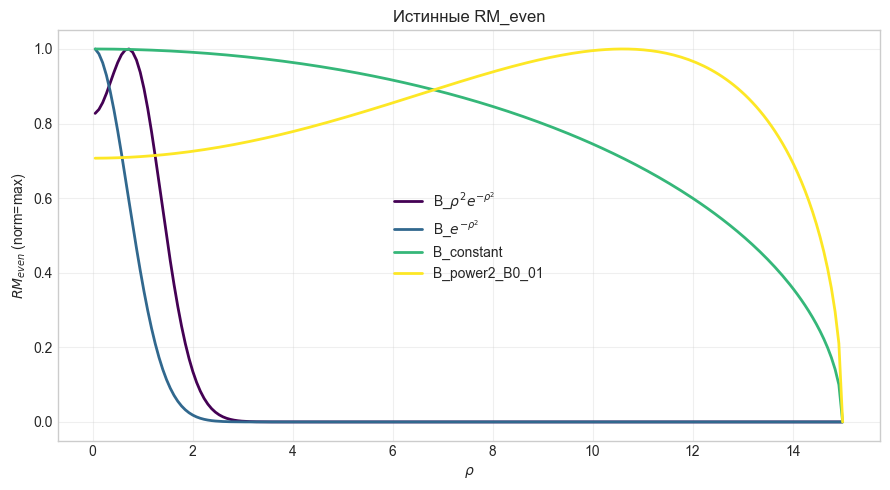

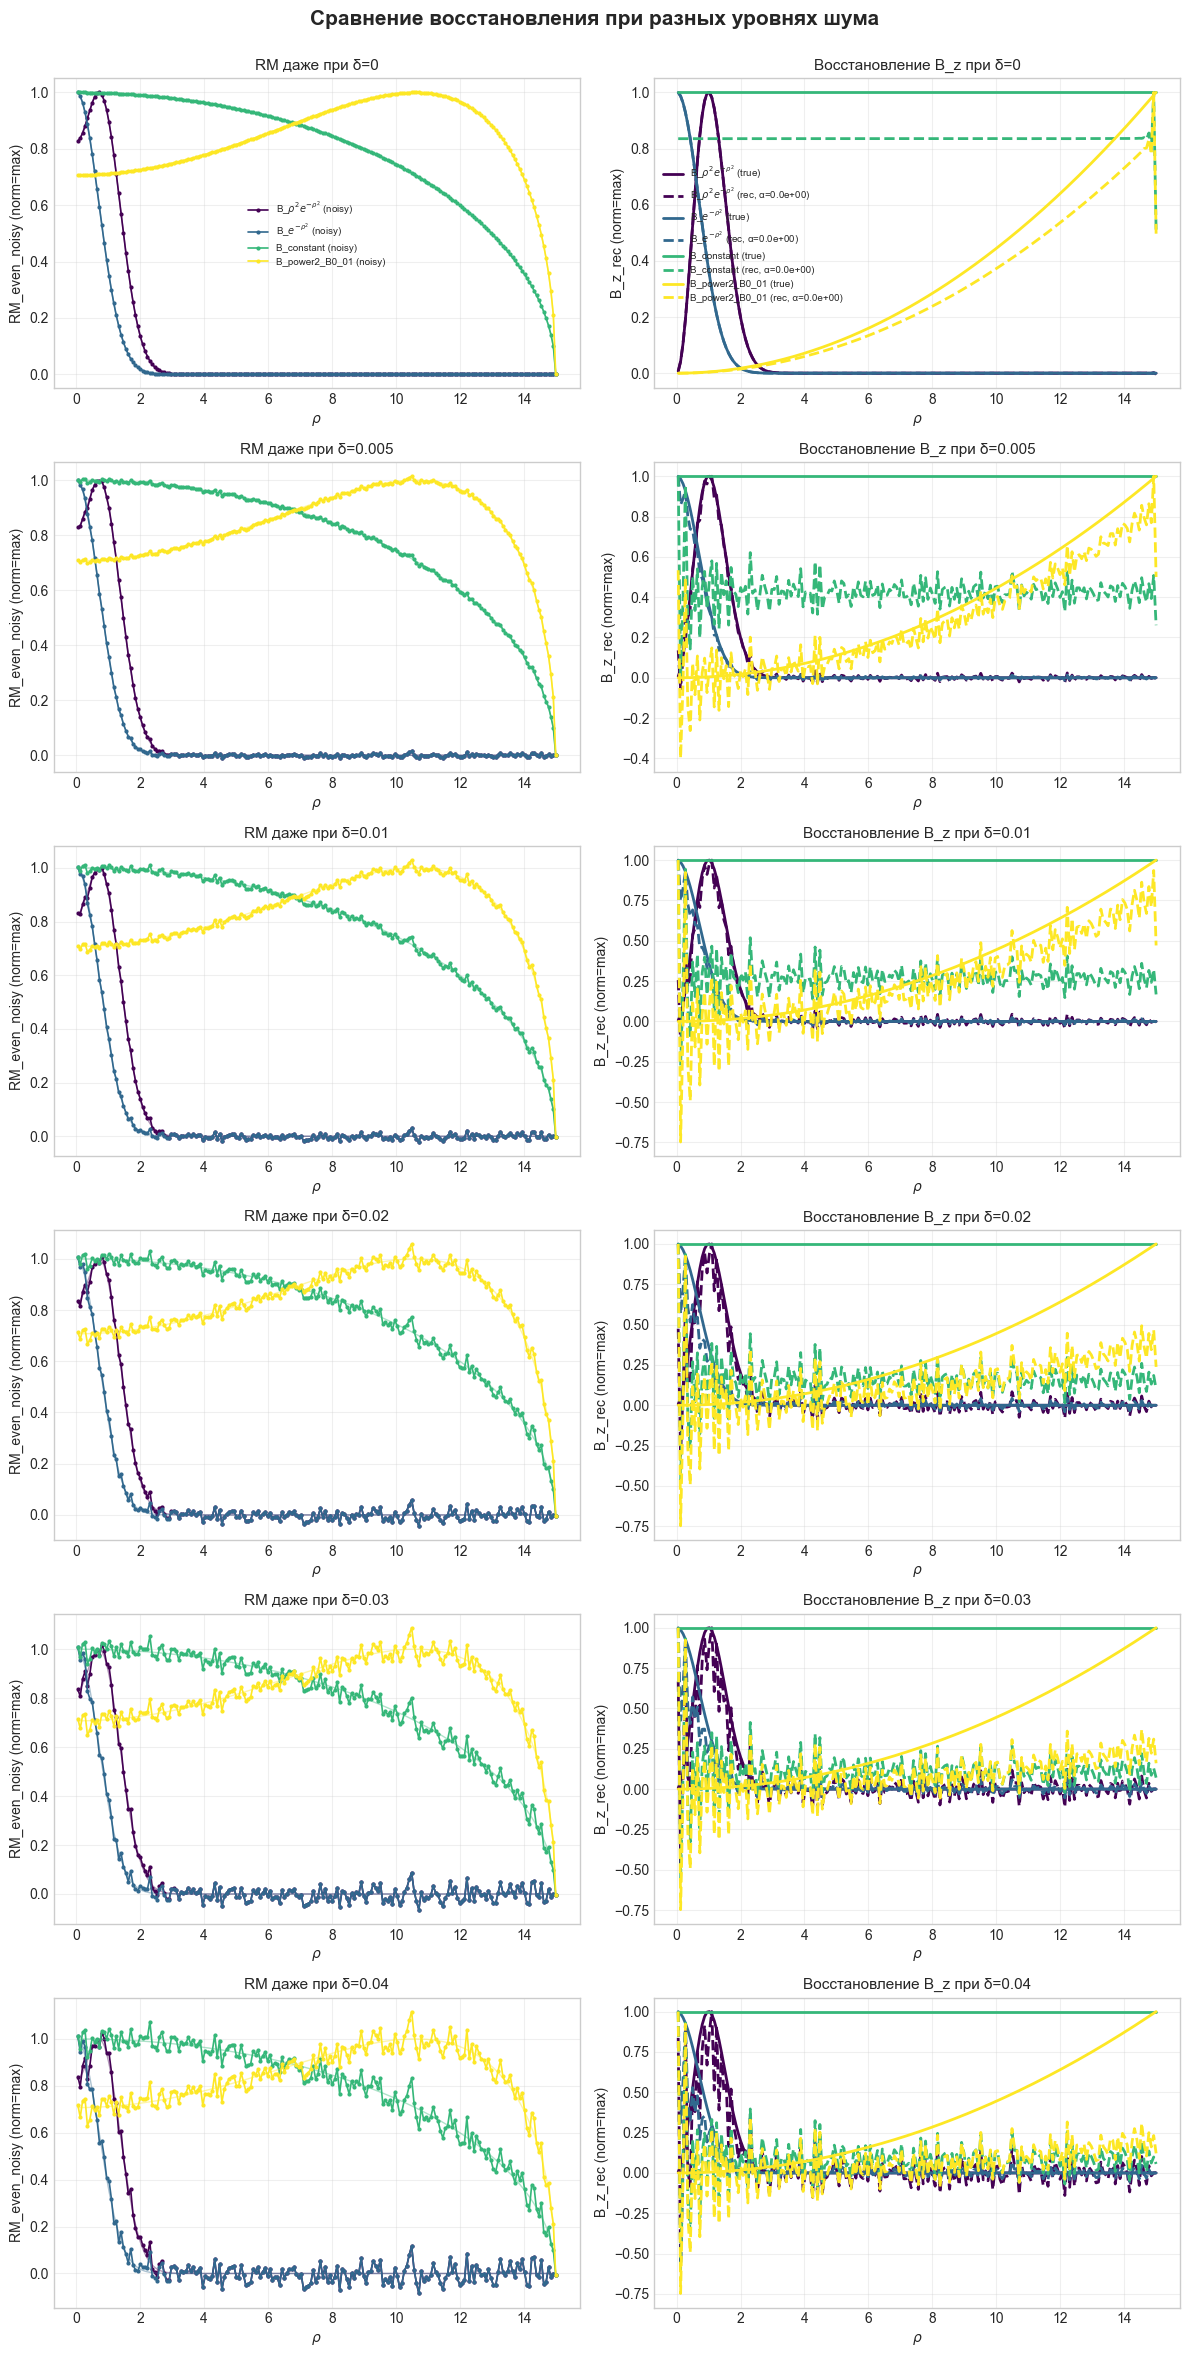

In [42]:
from methods import plot_noise_sweep_grid
csv_paths = {}

for delta_tmp in deltas:
    filename = _fname(delta_tmp, REG_KIND)
    csv_paths[delta_tmp] = filename
    
rho, runs = load_runs(csv_paths[deltas[0]])
# 1) Все истинные B_z на одном графике
plot_all_true_fields(rho, runs, field_key='B_z_true',
                        ylabel=r'$B_z$',
                        title="Истинные B_z",
                        norm = "max")

# 2) Все RM_even (истинные) на одном графике
plot_all_rm(rho, runs, rm_key='RM_even_true',
            ylabel=r'$RM_{even}$',
            title="Истинные RM_even",
            norm = "max")

plot_noise_sweep_grid(
    csv_paths,
    deltas=sorted(csv_paths.keys()),
    norm=  "max", # None, "max"
    title="Сравнение восстановления при разных уровнях шума",
)


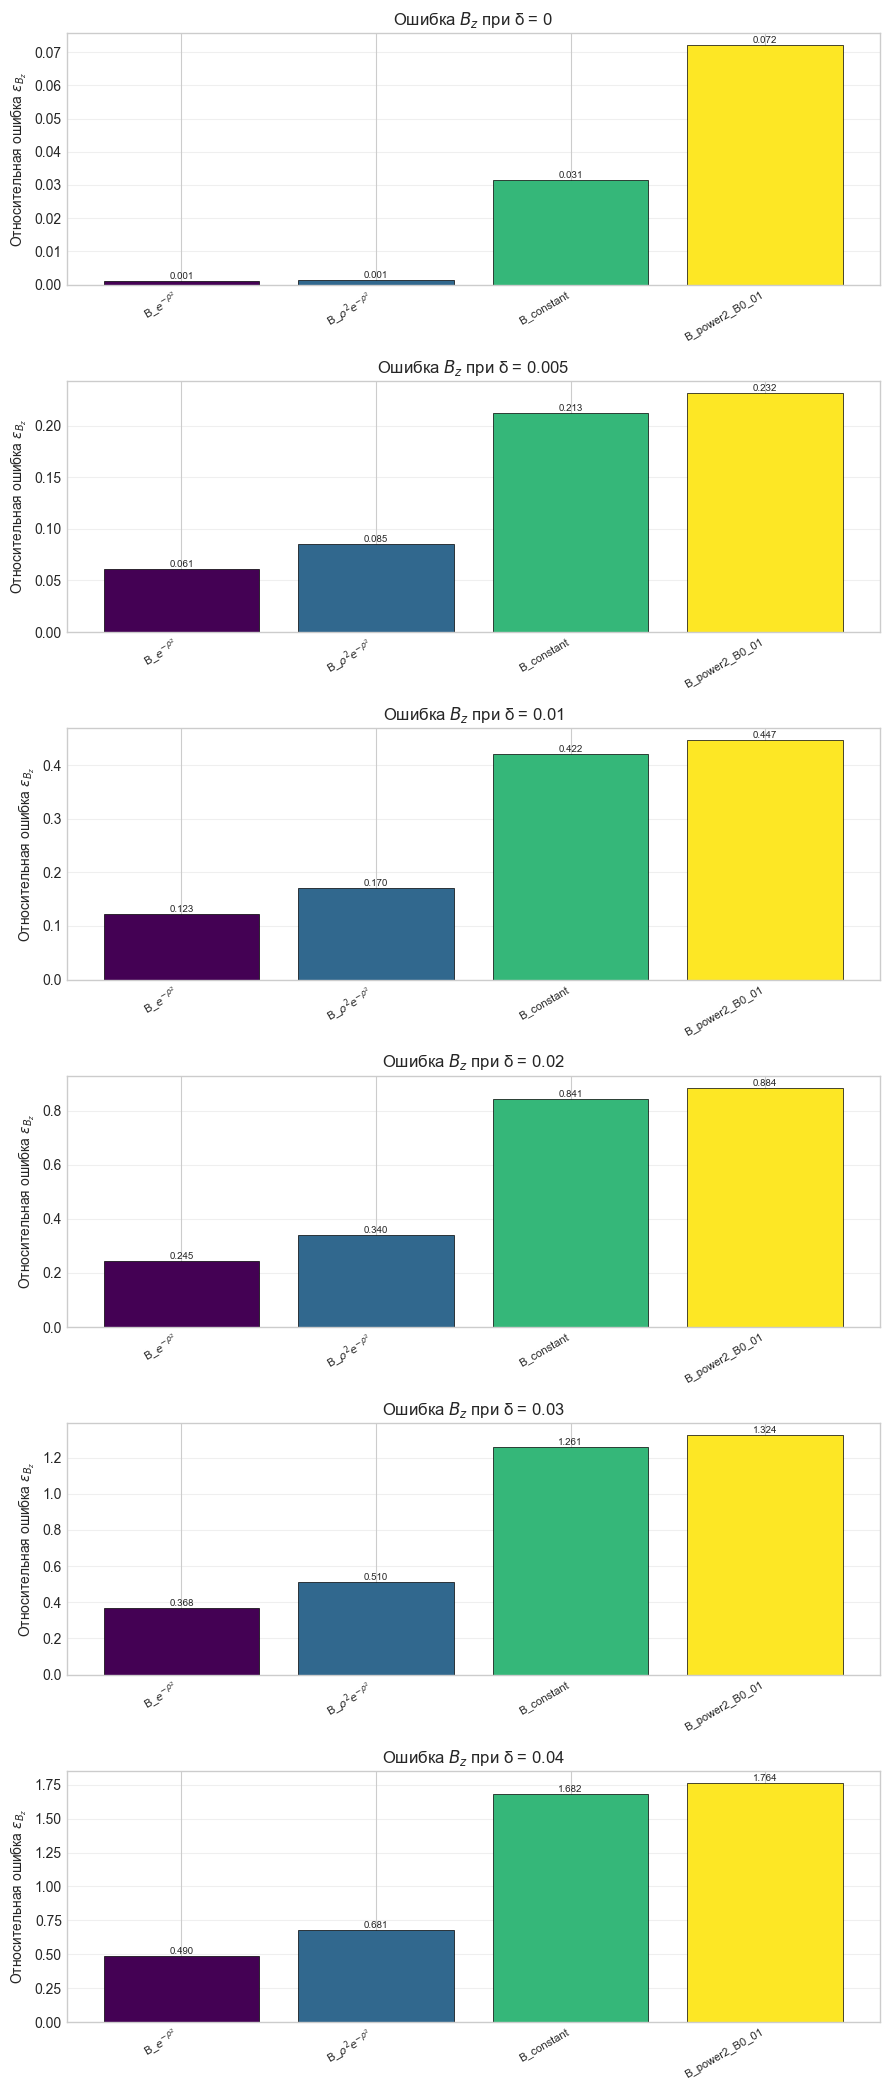

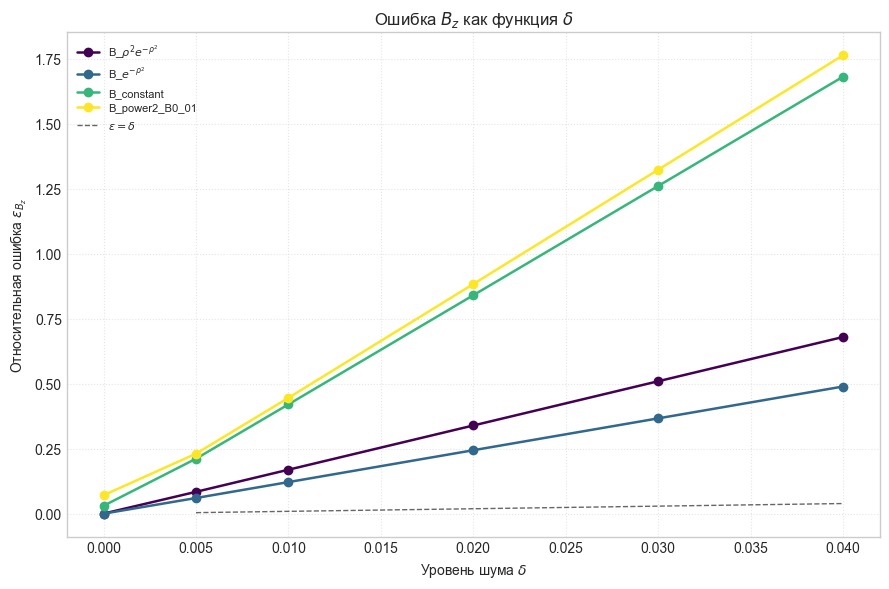

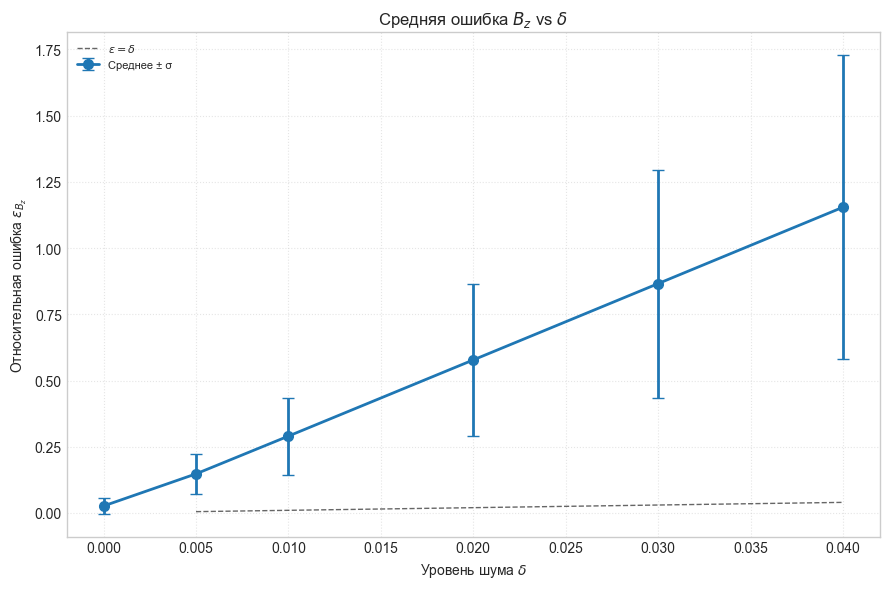

,delta,run,err_Bz_mean
1,0.000,B_$e^{-\rho^2}$,0.001076
0,0.000,B_$\rho^2 e^{-\rho^2}$,0.001319
2,0.000,B_constant,0.031363
3,0.000,B_power2_B0_01,0.072085
5,0.005,B_$e^{-\rho^2}$,0.061278
4,0.005,B_$\rho^2 e^{-\rho^2}$,0.085077
6,0.005,B_constant,0.212506
7,0.005,B_power2_B0_01,0.231844
9,0.010,B_$e^{-\rho^2}$,0.122541
8,0.010,B_$\rho^2 e^{-\rho^2}$,0.170139


In [43]:
# ==============================================================================
# СВОДНЫЕ ГРАФИКИ ОШИБОК + ЗАВИСИМОСТЬ ОТ δ
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from methods import load_runs, plot_all_errors_bar, plot_error_vs_noise

csv_paths = {d: _fname(d, REG_KIND) for d in deltas}

# --- 1) Столбчатые диаграммы для каждого δ ---
fig, axes = plt.subplots(len(deltas), 1, figsize=(9, 3.5 * len(deltas)))
if len(deltas) == 1: axes = [axes]

for ax, d in zip(axes, deltas):
    f = csv_paths[d]
    if not os.path.exists(f):
        ax.axis('off'); ax.set_title(f"δ={d} — нет файла"); continue
    rho, runs = load_runs(f)
    plot_all_errors_bar(rho, runs, err_key='err_Bz',
                        title=f"Ошибка $B_z$ при δ = {d}", ax=ax)
plt.tight_layout(); plt.show()

fl_LOGLOG = False
# --- 2) Ошибка vs δ: по кривой на каждый run ---
fig, ax = plt.subplots(figsize=(9, 6))
plot_error_vs_noise(csv_paths, deltas, err_key='err_Bz',
                    title=r"Ошибка $B_z$ как функция $\delta$",
                    ax=ax, loglog=fl_LOGLOG, annotate_runs=True)
plt.tight_layout(); plt.show()

# --- 3) Ошибка vs δ: усреднение по запускам ± σ ---
fig, ax = plt.subplots(figsize=(9, 6))
plot_error_vs_noise(csv_paths, deltas, err_key='err_Bz',
                    title=r"Средняя ошибка $B_z$ vs $\delta$",
                    ax=ax, loglog=fl_LOGLOG, annotate_runs=False)
plt.tight_layout(); plt.show()

# --- 4) Численная сводка ---
rows = []
for d in deltas:
    f = csv_paths[d]
    if not os.path.exists(f): continue
    _, runs = load_runs(f)
    for name, data in runs.items():
        if 'err_Bz' in data:
            rows.append({'delta': d, 'run': name,
                         'err_Bz_mean': float(np.mean(np.atleast_1d(data['err_Bz'])))})
df_err = pd.DataFrame(rows).sort_values(['delta', 'err_Bz_mean'])
df_err.to_csv(os.path.join(RESULTS_DIR, "summary_errors.csv"), index=False)
df_err